In [2]:
%pip install numpy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import numpy as np

 Our system aren't true random, they are pseudo random they generate random number through mathematical equation which require a starting value when not provide numpy take current time as starting value.

 Seed is used to provide a starting value to random function so that the random value it generate can be reproduces on successive runs.

 It is used for debugging purpose. 

In [4]:
np.random.seed(42)

In [5]:
print(np.random.random((3, 2)))

[[0.37454012 0.95071431]
 [0.73199394 0.59865848]
 [0.15601864 0.15599452]]


In [6]:
#it generate 20 data points of two dimension so it is more like passing matrix dimension
# the only difference between rand() and random() is how they accept the arugments or the dimensions
# rand take as individual integers while random take as tuple of integers
X = np.random.rand(20, 2) 
print(X)

[[0.05808361 0.86617615]
 [0.60111501 0.70807258]
 [0.02058449 0.96990985]
 [0.83244264 0.21233911]
 [0.18182497 0.18340451]
 [0.30424224 0.52475643]
 [0.43194502 0.29122914]
 [0.61185289 0.13949386]
 [0.29214465 0.36636184]
 [0.45606998 0.78517596]
 [0.19967378 0.51423444]
 [0.59241457 0.04645041]
 [0.60754485 0.17052412]
 [0.06505159 0.94888554]
 [0.96563203 0.80839735]
 [0.30461377 0.09767211]
 [0.68423303 0.44015249]
 [0.12203823 0.49517691]
 [0.03438852 0.9093204 ]
 [0.25877998 0.66252228]]


In [7]:
from sklearn.neighbors import NearestNeighbors

In [8]:
k = 4
neigh = NearestNeighbors(n_neighbors=k, algorithm='brute', metric='euclidean')
neigh.fit(X)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",4
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'brute'
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'euclidean'
,"radius radius: float, default=1.0Range of parameter space to use by default for :meth:`radius_neighbors`queries.",1.0
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float (positive), default=2Parameter for the Minkowski metric fromsklearn.metrics.pairwise.pairwise_distances. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
Name,Type,Value
effective_metric_ effective_metric_: strMetric used to compute distances to neighbors.,str,'eu...an'
effective_metric_params_ effective_metric_params_: dictParameters for the metric used to compute distances to neighbors.,dict,{}


In [9]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


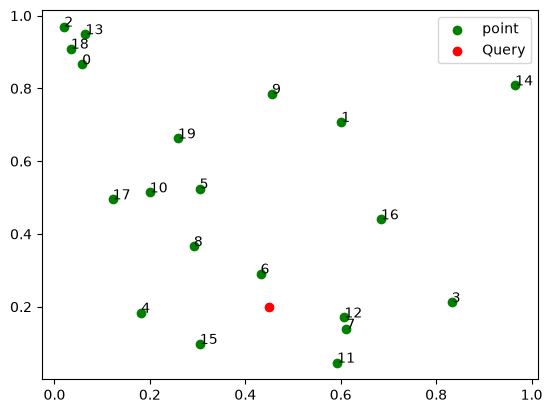

In [10]:
import matplotlib.pyplot as plt

n = range(len(X))

fig, ax = plt.subplots()
ax.scatter(X[:,0], X[:,1], c='green', label='point')
ax.scatter(0.45, 0.2, c='red', label='Query')
ax.legend()

for i, txt in enumerate(n):
    ax.annotate(txt, (X[i, 0], X[i, 1]))

In [11]:
import time

In [12]:

t1 = time.time()
neighbors = neigh.kneighbors([[0.45, 0.2],[0.5, 0.8]], 4, return_distance=True)
t2 = time.time()
print('query time: ', t2 - t1)
print(neighbors)

query time:  0.03590869903564453
(array([[0.09299859, 0.16027853, 0.1727928 , 0.17778682],
       [0.04636376, 0.13665613, 0.27764585, 0.33775749]]), array([[ 6, 12,  7, 15],
       [ 9,  1, 19,  5]]))


why are we normalizing it?

we normalize because text embeddings/ semantic search cosine similarty fits better then anything else.

right now ```np.random.randn(documents, dimensions)``` values are random ranging between ``` [-infinity, +infinity] ```, the magnitude of the vector can affect the similarity score of embedding adversely, two vector which are more aligned to each other still can have less dot product then vectors poorly aligned but huge magnitude

therefore ```L2 normalization``` in which the magnitude of vector is reduced to ```1``` however the direction is preserved.

when the magnitude is ```1``` dot product is same as cosine similarity because 

```a dot b = |a||b|cosQ   ```

```a dot b = 1 * 1 * cosQ ```

```a dot b = cosQ         ```

also cosine similarity and euclidean distance yield the same ordering for vectors having magnitude 1

Because both have a length of 1: 
```|q| = |x| = 1```

Start with the squared Euclidean distance formula:
```|q-x|^2 = |q|^2+|x|^2-2(q dot x)```

Substitute the lengths of the normalized vectors:
```|q-x|^2=1^2+1^2-2(q dot x)```

Therefore:
```|q-x|^2=2-2(q dot x)```

```higher the score -> higher the cosine similarity```
```lower the score -> higher the eculidean similarty```

In [15]:
documents = 1000
dimensions = 768

embeddings = np.random.randn(documents, dimensions)
emdeddings = embeddings/np.sqrt((embeddings**2).sum(1, keepdims=True))

query = np.random.randn(768)
query = query / np.sqrt((query**2).sum())

In [18]:
t0 = time.time()

similarities = embeddings.dot(query)
#argsort return the order of indices in which if elements get arranged result in a sorted sequence from smallest to largest 
# we here put minus sign in front of similarities array so that we can get highest to smallest sequence
sorted_ix = np.argsort(-similarities)

t1 = time.time()

total = t1 - t0

print(F"Runtime for dime-{dimensions}, documents_n={documents}: {np.round(total, 3)} seconds")

for i in sorted_ix[:5]:
    print(similarities[i])

Runtime for dime-768, documents_n=1000: 0.001 seconds
3.1578312877266503
2.774529216705756
2.5612602541442584
2.5356934536826365
2.504206431077532
